In [ ]:
# This cell clones the 3W repository, extracts the dataset, and installs necessary Python packages.
import glob
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq
import shutil
import gc


os.chdir('/content/')

if os.path.exists('3W'):
    shutil.rmtree('3W')
if os.path.exists('dataset'):
    shutil.rmtree('dataset')

repo_url = 'https://github.com/petrobras/3W.git'
temp_clone_dir = '3W_repo_temp'
dataset_subdir_name = 'dataset'

print(f"Cloning '{repo_url}' (shallow clone) into '{temp_clone_dir}'...")
!git clone --depth 1 {repo_url} {temp_clone_dir}

source_path = os.path.join(temp_clone_dir, dataset_subdir_name)
destination_path = dataset_subdir_name

if os.path.exists(source_path):
    print(f"Moving '{source_path}' to '{destination_path}'...")
    shutil.move(source_path, destination_path)
    print(f"Successfully moved '{dataset_subdir_name}'.")
else:
    print(f"Error: The expected dataset directory '{source_path}' was not found after cloning.")

if os.path.exists(temp_clone_dir):
    print(f"Removing temporary clone directory '{temp_clone_dir}'...")
    shutil.rmtree(temp_clone_dir)

%cd dataset


Cloning 'https://github.com/petrobras/3W.git' (shallow clone) into '3W_repo_temp'...
Cloning into '3W_repo_temp'...
remote: Enumerating objects: 2577, done.
remote: Counting objects: 100% (2577/2577), done.
remote: Compressing objects: 100% (2558/2558), done.
remote: Total 2577 (delta 20), reused 2416 (delta 12), pack-reused 0 (from 0)
Receiving objects: 100% (2577/2577), 1.85 GiB | 31.74 MiB/s, done.
Resolving deltas: 100% (20/20), done.
Updating files: 100% (2521/2521), done.
Moving '3W_repo_temp/dataset' to 'dataset'...
Successfully moved 'dataset'.
Removing temporary clone directory '3W_repo_temp'...
/content/dataset


In [ ]:
# This cell imports libraries, sets global plot styling, defines the dataset path, and maps labels for anomaly classes.

sns.set_theme(style="whitegrid")

DATASET_PATH = "."

# Label mapping according to 3W dataset specs
LABEL_MAP = {
    0: "NORMAL",
    1: "ABRUPT_INCREASE_OF_BSW",
    2: "SPURIOUS_CLOSURE_OF_DHSV",
    3: "SEVERE_SLUGGING",
    4: "FLOW_INSTABILITY",
    5: "RAPID_PRODUCTIVITY_LOSS",
    6: "QUICK_RESTRICTION_IN_PCK",
    7: "SCALING_IN_PCK",
    8: "HYDRATE_IN_PRODUCTION_LINE",
    9: "HYDRATE_IN_SERVICE_LINE"
}

def map_transient_classes(y):
    """Maps transient state classes (e.g. 101 -> 1) to match base event classes."""
    return y.apply(lambda c: c - 100 if c >= 100 else c)

print("Environment setup complete.")

Environment setup complete.


In [31]:
# This cell extracts state transitions and anomaly event occurrences from parquet files incrementally.
parquet_files = glob.glob(os.path.join(DATASET_PATH, "**/*.parquet"), recursive=True)

if not parquet_files:
    raise FileNotFoundError("No parquet files found in the dataset directory.")

print(f"Found {len(parquet_files)} parquet files. Extracting transition matrix & event occurrences...")

all_transitions = []
anomaly_event_counts = pd.Series(dtype=int)

for idx, file_path in enumerate(parquet_files, 1):
    try:
        # Memory Optimization: Read ONLY the 'class' column
        df_class = pd.read_parquet(file_path, columns=['class'])
    except Exception:
        continue

    if 'class' not in df_class.columns or df_class['class'].dropna().empty:
        continue

    # Map transient classes (100+ offset) to base classes
    classes = map_transient_classes(df_class['class'].dropna().astype(int))

    if len(classes) < 2:
        continue

    # 1. Extract State Transitions (From Class -> To Class)
    prev_classes = classes.shift(1).dropna()
    curr_classes = classes.iloc[1:]

    # Capture state transitions where state actually changes
    transitions = pd.DataFrame({
        'From_Class': prev_classes.values,
        'To_Class': curr_classes.values
    })

    # Keep only actual state change transitions to keep DataFrame small
    state_changes = transitions[transitions['From_Class'] != transitions['To_Class']]
    all_transitions.append(state_changes)

    # 2. Track Event Occurrences
    # Identify unique event start blocks
    change_points = np.diff(classes.values) != 0
    block_starts = np.insert(change_points, 0, True)
    block_classes = classes.values[block_starts]

    # Filter out normal state (class 0) for occurrence counting
    anomalies_only = block_classes[block_classes != 0]
    file_counts = pd.Series(anomalies_only).value_counts()
    anomaly_event_counts = anomaly_event_counts.add(file_counts, fill_value=0)

    del df_class, classes, transitions

    if idx % 50 == 0 or idx == len(parquet_files):
        gc.collect()
        print(f"Processed {idx}/{len(parquet_files)} files...")

# Aggregate all transitions into a single DataFrame
full_transitions_df = pd.concat(all_transitions, ignore_index=True) if all_transitions else pd.DataFrame()

print(f"\nProcessing Complete!")
print(f"Total State Changes Recorded: {len(full_transitions_df):,}")

Found 2228 parquet files. Extracting transition matrix & event occurrences...
Processed 50/2228 files...
Processed 100/2228 files...
Processed 150/2228 files...
Processed 200/2228 files...
Processed 250/2228 files...
Processed 300/2228 files...
Processed 350/2228 files...
Processed 400/2228 files...
Processed 450/2228 files...
Processed 500/2228 files...
Processed 550/2228 files...
Processed 600/2228 files...
Processed 650/2228 files...
Processed 700/2228 files...
Processed 750/2228 files...
Processed 800/2228 files...
Processed 850/2228 files...
Processed 900/2228 files...
Processed 950/2228 files...
Processed 1000/2228 files...
Processed 1050/2228 files...
Processed 1100/2228 files...
Processed 1150/2228 files...
Processed 1200/2228 files...
Processed 1250/2228 files...
Processed 1300/2228 files...
Processed 1350/2228 files...
Processed 1400/2228 files...
Processed 1450/2228 files...
Processed 1500/2228 files...
Processed 1550/2228 files...
Processed 1600/2228 files...
Processed 1650

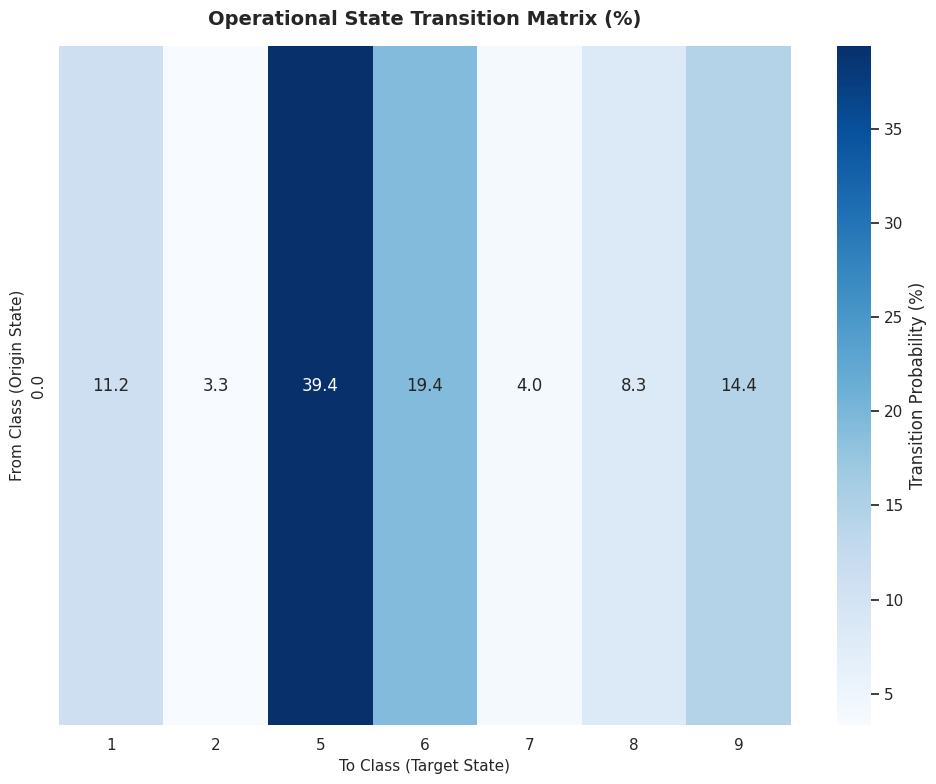

Saved: state_transition_matrix.png


In [32]:
# This cell plots the operational state transition matrix.
if not full_transitions_df.empty:

    transition_matrix = pd.crosstab(
        full_transitions_df['From_Class'],
        full_transitions_df['To_Class'],
        normalize='index'
    ) * 100  # Convert to percentages

    labels = [f"{k}: {v}" for k, v in LABEL_MAP.items() if k in transition_matrix.index or k in transition_matrix.columns]

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        transition_matrix,
        annot=True,
        fmt=".1f",
        cmap="Blues",
        cbar_kws={'label': 'Transition Probability (%)'}
    )

    plt.title("Operational State Transition Matrix (%)", fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("To Class (Target State)", fontsize=11)
    plt.ylabel("From Class (Origin State)", fontsize=11)

    plt.tight_layout()
    plt.savefig("state_transition_matrix.png", dpi=300)
    plt.show()
    print("Saved: state_transition_matrix.png")
else:
    print("No transition data captured.")

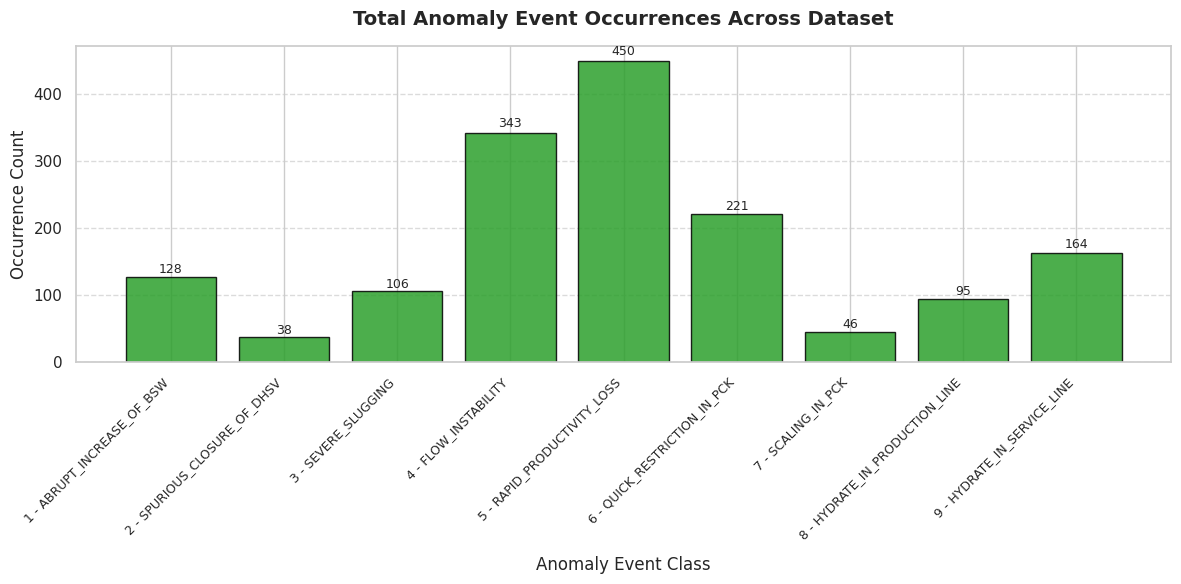

Saved: total_anomaly_occurrences.png


In [33]:
# This cell plots the total anomaly event occurrences across the dataset.
if not anomaly_event_counts.empty:

    occurrence_df = anomaly_event_counts.reset_index()
    occurrence_df.columns = ['class', 'occurrence_count']
    occurrence_df['class_name'] = occurrence_df['class'].map(LABEL_MAP)
    occurrence_df = occurrence_df.sort_values(by='class')

    plt.figure(figsize=(12, 6))
    bars = plt.bar(
        occurrence_df['class'].astype(str) + " - " + occurrence_df['class_name'],
        occurrence_df['occurrence_count'],
        color='#2ca02c',
        edgecolor='black',
        alpha=0.85
    )

    plt.title("Total Anomaly Event Occurrences Across Dataset", fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Anomaly Event Class", fontsize=12, labelpad=10)
    plt.ylabel("Occurrence Count", fontsize=12)
    plt.xticks(rotation=45, ha='right', fontsize=9)
    plt.grid(axis='y', linestyle='--', alpha=0.7)


    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2.0, yval + (yval * 0.01), f'{int(yval)}', ha='center', va='bottom', fontsize=9)

    plt.tight_layout()
    plt.savefig("total_anomaly_occurrences.png", dpi=300)
    plt.show()
    print("Saved: total_anomaly_occurrences.png")
else:
    print("No anomaly occurrences found.")

In [34]:
# This cell processes parquet files to create instance-level records, including details about anomaly events.
EVENT_NAMES = {k: v for k, v in LABEL_MAP.items() if k > 0}
files = sorted(glob.glob(os.path.join(DATASET_PATH, "**/*.parquet"), recursive=True))
records = []
for fp in files:
    name = os.path.basename(fp)
    s = pd.read_parquet(fp, columns=["class"])["class"]
    cls = s.to_numpy(dtype="float64", na_value=np.nan)
    ts = s.index
    valid = ~np.isnan(cls)
    fault = valid & (cls >= 1) & (cls < 100)
    trans = valid & (cls >= 100)
    abn = fault | trans
    source = ("REAL" if name.startswith("WELL") else
              "SIMULATED" if name.startswith("SIMULATED") else "DRAWN")
    records.append(dict(
        file=name,
        source=source,
        well=name.split("_")[0] if source == "REAL" else None,
        event_class=int((cls[abn] % 100).max()) if abn.any() else 0,
        rows=len(cls),
        transient_h=trans.sum() / 3600,
        fault_h=fault.sum() / 3600,
        has_fault=bool(fault.any()),
        abn_start=ts[abn][0] if abn.any() else pd.NaT,
        abn_end=ts[abn][-1] if abn.any() else pd.NaT,
    ))
inst = pd.DataFrame(records)
print(f"{len(inst)} instances | {inst.well.nunique()} distinct real wells")
print(inst.groupby("source").size().to_string())

2228 instances | 40 distinct real wells
source
DRAWN          20
REAL         1119
SIMULATED    1089


source,REAL,SIMULATED,DRAWN,total,real_share_%
1 - ABRUPT_INCREASE_OF_BSW,4,114,10,128,3.1
2 - SPURIOUS_CLOSURE_OF_DHSV,22,16,0,38,57.9
3 - SEVERE_SLUGGING,32,74,0,106,30.2
4 - FLOW_INSTABILITY,343,0,0,343,100.0
5 - RAPID_PRODUCTIVITY_LOSS,11,439,0,450,2.4
6 - QUICK_RESTRICTION_IN_PCK,6,215,0,221,2.7
7 - SCALING_IN_PCK,36,0,10,46,78.3
8 - HYDRATE_IN_PRODUCTION_LINE,14,81,0,95,14.7
9 - HYDRATE_IN_SERVICE_LINE,14,150,0,164,8.5


Real files whose only label is NORMAL: 637


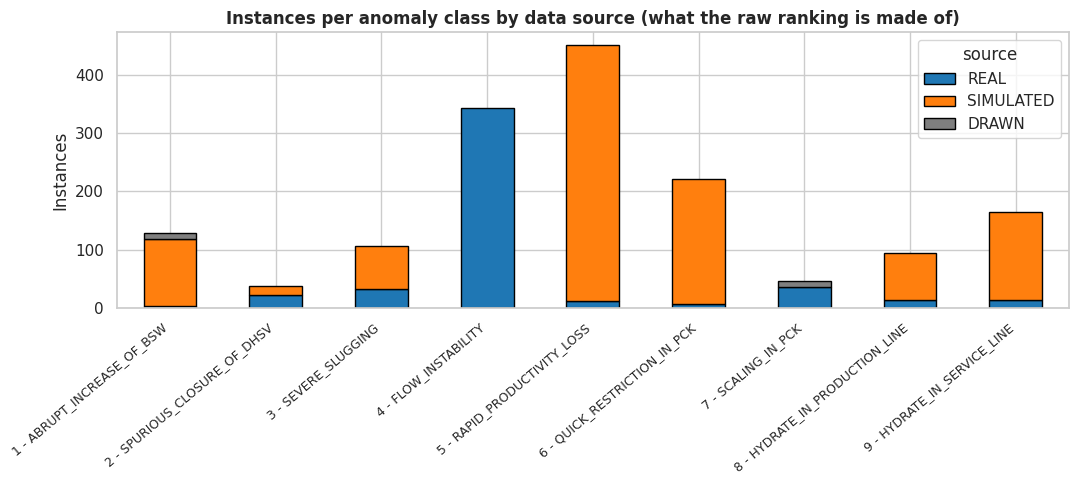

In [35]:
# This cell analyzes and visualizes the provenance of anomaly classes across different data sources.
prov = (inst[inst.event_class > 0]
        .groupby(["event_class", "source"]).size().unstack(fill_value=0)
        .reindex(columns=["REAL", "SIMULATED", "DRAWN"], fill_value=0))
prov["total"] = prov.sum(axis=1)
prov["real_share_%"] = (100 * prov["REAL"] / prov["total"]).round(1)
prov.index = [f"{i} - {EVENT_NAMES[i]}" for i in prov.index]
display(prov)

n_normal_only = ((inst.event_class == 0) & (inst.source == "REAL")).sum()
print(f"Real files whose only label is NORMAL: {n_normal_only}")

fig, ax = plt.subplots(figsize=(11, 5))
prov[["REAL", "SIMULATED", "DRAWN"]].plot(kind="bar", stacked=True, ax=ax,
                                          color=["#1f77b4", "#ff7f0e", "#7f7f7f"], edgecolor="black")
ax.set_title("Instances per anomaly class by data source (what the raw ranking is made of)", fontweight="bold")
ax.set_ylabel("Instances"); ax.set_xlabel("")
plt.xticks(rotation=40, ha="right", fontsize=9); plt.tight_layout()
plt.savefig("provenance_by_class.png", dpi=300); plt.show()

,event,instances,episodes,wells,episodes_per_affected_well,%_of_real_wells_affected,%_of_episodes
event_class,,,,,,,
7,SCALING_IN_PCK,36,36,6,6.00,18.2,26.1
4,FLOW_INSTABILITY,343,27,7,3.86,21.2,19.6
2,SPURIOUS_CLOSURE_OF_DHSV,22,22,7,3.14,21.2,15.9
9,HYDRATE_IN_SERVICE_LINE,14,14,7,2.00,21.2,10.1
8,HYDRATE_IN_PRODUCTION_LINE,14,14,9,1.56,27.3,10.1
5,RAPID_PRODUCTIVITY_LOSS,11,10,3,3.33,9.1,7.2
3,SEVERE_SLUGGING,32,7,2,3.50,6.1,5.1
1,ABRUPT_INCREASE_OF_BSW,4,4,3,1.33,9.1,2.9
6,QUICK_RESTRICTION_IN_PCK,6,4,2,2.00,6.1,2.9


138 independent real episodes across 33 real wells


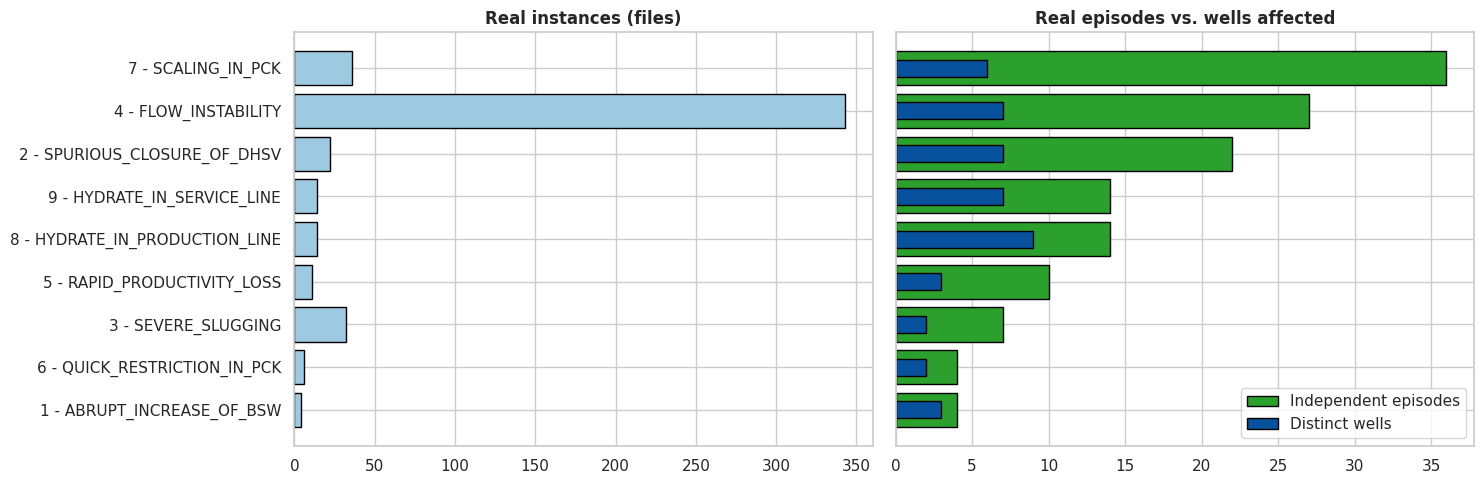

In [36]:
# This cell identifies and analyzes independent real episodes by merging instances of the same well and class that overlap.
EPISODE_GAP_H = 1.0

real = inst[(inst.source == "REAL") & (inst.event_class > 0)].sort_values(
    ["well", "event_class", "abn_start"]).copy()
prev_end = real.groupby(["well", "event_class"])["abn_end"].transform(lambda x: x.cummax().shift())
gap_h = (real["abn_start"] - prev_end).dt.total_seconds() / 3600
real["episode_id"] = (gap_h.isna() | (gap_h > EPISODE_GAP_H)).cumsum()

ep = real.groupby("episode_id").agg(
    well=("well", "first"), event_class=("event_class", "first"),
    start=("abn_start", "min"), end=("abn_end", "max"),
    instances=("file", "size"), transient_h=("transient_h", "sum"), has_fault=("has_fault", "max"))
ep["duration_h"] = (ep["end"] - ep["start"]).dt.total_seconds() / 3600 + 1 / 3600
# onset = time spent in the transient phase before the fault is fully developed
ep["onset_min"] = np.where(ep.has_fault & (ep.transient_h > 0), ep.transient_h * 60, np.nan)

n_wells = ep.well.nunique()
freq = ep.groupby("event_class").agg(
    instances=("instances", "sum"), episodes=("well", "size"), wells=("well", "nunique"))
freq["episodes_per_affected_well"] = (freq.episodes / freq.wells).round(2)
freq["%_of_real_wells_affected"] = (100 * freq.wells / n_wells).round(1)
freq["%_of_episodes"] = (100 * freq.episodes / freq.episodes.sum()).round(1)
freq.insert(0, "event", [EVENT_NAMES[i] for i in freq.index])
display(freq.sort_values("episodes", ascending=False))
print(f"{len(ep)} independent real episodes across {n_wells} real wells")

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
order = freq.sort_values("episodes").index
lab = [f"{i} - {EVENT_NAMES[i]}" for i in order]
axes[0].barh(lab, freq.loc[order, "instances"], color="#9ecae1", edgecolor="black")
axes[0].set_title("Real instances (files)", fontweight="bold")
axes[1].barh(lab, freq.loc[order, "episodes"], color="#2ca02c", edgecolor="black", label="Independent episodes")
axes[1].barh(lab, freq.loc[order, "wells"], color="#08519c", edgecolor="black", height=0.4, label="Distinct wells")
axes[1].set_title("Real episodes vs. wells affected", fontweight="bold"); axes[1].legend()
plt.tight_layout(); plt.savefig("real_frequency.png", dpi=300); plt.show()

Top 3 wells account for 32.6% of real episodes
Wells with 2+ different event types: 8 of 33
Wells with 3+ episodes of the same type: 14 of 33


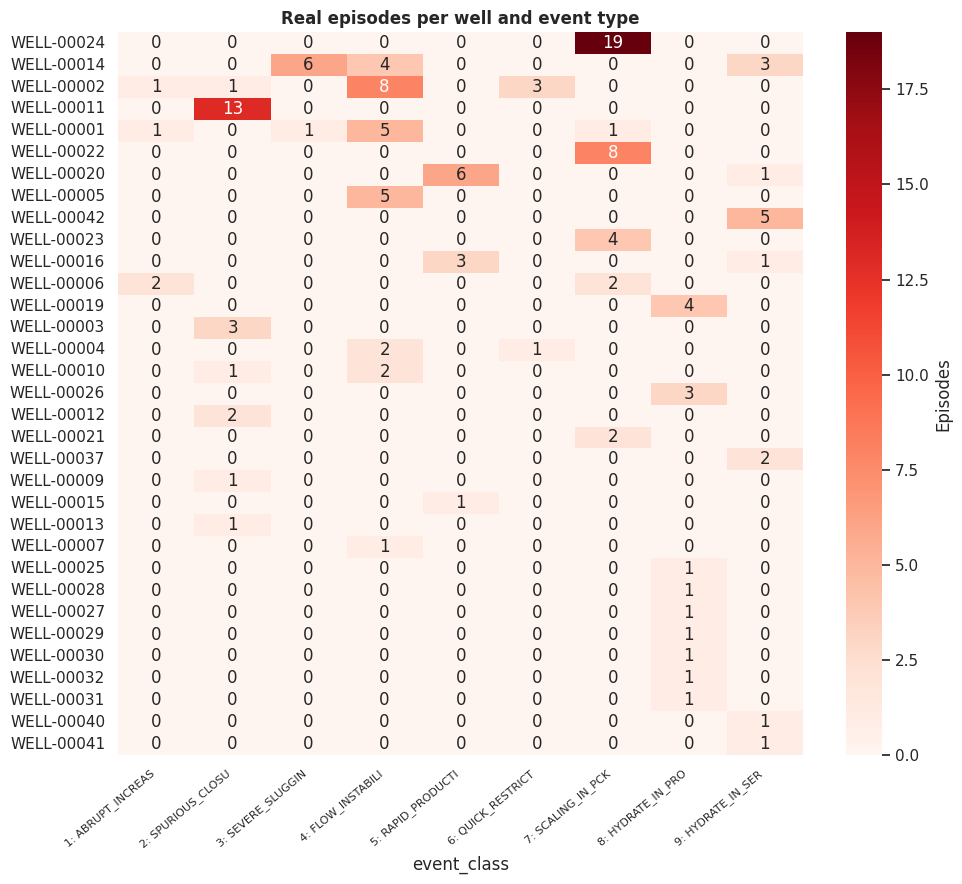

,1: ABRUPT_INCREAS,2: SPURIOUS_CLOSU,3: SEVERE_SLUGGIN,4: FLOW_INSTABILI,5: RAPID_PRODUCTI,6: QUICK_RESTRICT,7: SCALING_IN_PCK,8: HYDRATE_IN_PRO,9: HYDRATE_IN_SER
year,,,,,,,,,
2011,0,0,0,0,0,0,0,1,0
2012,0,0,0,0,0,0,0,1,0
2013,0,1,0,3,0,0,0,0,1
2014,2,14,0,7,6,3,0,3,5
2015,0,0,0,0,0,0,0,1,1
2016,0,0,0,0,0,0,19,1,2
2017,1,6,7,15,1,1,1,2,1
2018,1,1,0,2,3,0,15,0,4
2019,0,0,0,0,0,0,1,0,0


In [37]:
# This cell analyzes the concentration and recurrence of events per well and visualizes them using a heatmap.
well_ev = ep.pivot_table(index="well", columns="event_class", values="instances",
                         aggfunc="size", fill_value=0)
well_ev["total"] = well_ev.sum(axis=1)
well_ev = well_ev.sort_values("total", ascending=False)

top3 = well_ev.head(3)["total"].sum() / well_ev["total"].sum() * 100
print(f"Top 3 wells account for {top3:.1f}% of real episodes")
print(f"Wells with 2+ different event types: {(well_ev.drop(columns='total') > 0).sum(axis=1).ge(2).sum()} of {len(well_ev)}")
print(f"Wells with 3+ episodes of the same type: "
      f"{(well_ev.drop(columns='total') >= 3).any(axis=1).sum()} of {len(well_ev)}")

fig, ax = plt.subplots(figsize=(10, 9))
sns.heatmap(well_ev.drop(columns="total").rename(columns=lambda c: f"{c}: {EVENT_NAMES[c][:14]}"),
            annot=True, fmt="d", cmap="Reds", cbar_kws={"label": "Episodes"}, ax=ax)
ax.set_title("Real episodes per well and event type", fontweight="bold"); ax.set_ylabel("")
plt.xticks(rotation=40, ha="right", fontsize=8); plt.tight_layout()
plt.savefig("well_event_heatmap.png", dpi=300); plt.show()

by_year = ep.assign(year=ep.start.dt.year).pivot_table(index="year", columns="event_class",
                                                      values="well", aggfunc="size", fill_value=0)
by_year.columns = [f"{c}: {EVENT_NAMES[c][:14]}" for c in by_year.columns]
display(by_year)

,event,episodes,wells,%_of_real_wells_affected,median_h,p90_h,total_abnormal_h,%_of_abnormal_hours,median_onset_min,freq_rank,exposure_rank
event_class,,,,,,,,,,,
7,SCALING_IN_PCK,36,6,18.2,40.17,111.16,1861.37,46.9,720.40,1,1
8,HYDRATE_IN_PRODUCTION_LINE,14,9,27.3,65.30,159.79,1054.54,26.6,2902.47,4,2
4,FLOW_INSTABILITY,27,7,21.2,13.99,54.37,686.66,17.3,NaN,2,3
3,SEVERE_SLUGGING,7,2,6.1,14.98,46.98,158.89,4.0,NaN,7,4
5,RAPID_PRODUCTIVITY_LOSS,10,3,9.1,6.94,15.46,92.97,2.3,153.00,6,5
9,HYDRATE_IN_SERVICE_LINE,14,7,21.2,3.43,10.67,59.22,1.5,103.35,4,6
2,SPURIOUS_CLOSURE_OF_DHSV,22,7,21.2,0.85,3.04,30.66,0.8,85.82,3,7
1,ABRUPT_INCREASE_OF_BSW,4,3,9.1,3.49,9.05,20.87,0.5,163.62,8,8
6,QUICK_RESTRICTION_IN_PCK,4,2,6.1,1.64,2.35,6.33,0.2,27.52,8,9


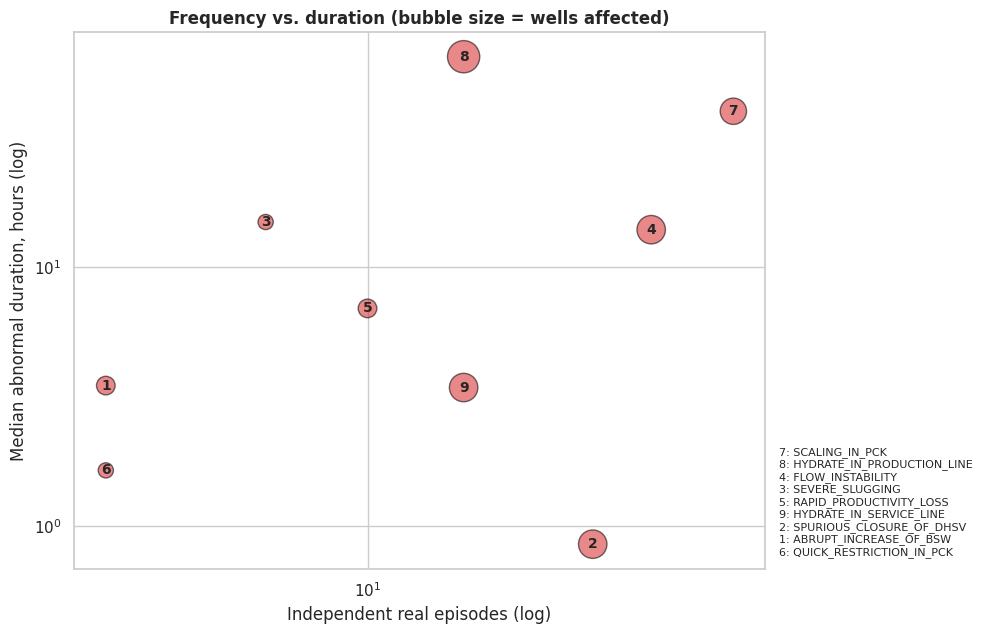

In [38]:
# This cell generates a one-page summary for stakeholders, including risk metrics and a plot of event frequency vs. duration.
risk = freq[["event", "episodes", "wells", "%_of_real_wells_affected"]].join(
    dur[["median_h", "p90_h", "total_abnormal_h", "%_of_abnormal_hours", "median_onset_min"]])
risk["freq_rank"] = risk.episodes.rank(ascending=False, method="min").astype(int)
risk["exposure_rank"] = risk.total_abnormal_h.rank(ascending=False, method="min").astype(int)
risk = risk.sort_values("exposure_rank")
display(risk)
risk.to_csv("insurance_anomaly_summary.csv")

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.scatter(risk.episodes, risk.median_h, s=risk.wells * 60, alpha=0.55, color="#d62728", edgecolor="black")
for i, r in risk.iterrows():
    ax.annotate(f"{i}", (r.episodes, r.median_h), ha="center", va="center", fontsize=10, fontweight="bold")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Independent real episodes (log)"); ax.set_ylabel("Median abnormal duration, hours (log)")
ax.set_title("Frequency vs. duration (bubble size = wells affected)", fontweight="bold")
ax.text(1.02, 0.02, "\n".join(f"{i}: {EVENT_NAMES[i]}" for i in risk.index),
        transform=ax.transAxes, fontsize=8, va="bottom")
plt.tight_layout(); plt.savefig("frequency_vs_duration.png", dpi=300, bbox_inches="tight"); plt.show()